┌ Warning: Found `resolution` in the theme when creating a `Scene`. The `resolution` keyword for `Scene`s and `Figure`s has been deprecated. Use `Figure(; size = ...` or `Scene(; size = ...)` instead, which better reflects that this is a unitless size and not a pixel resolution. The key could also come from `set_theme!` calls or related theming functions.
└ @ Makie C:\Users\vishw\.julia\packages\Makie\4JW9B\src\scenes.jl:264
┌ Warning: Found `resolution` in the theme when creating a `Scene`. The `resolution` keyword for `Scene`s and `Figure`s has been deprecated. Use `Figure(; size = ...` or `Scene(; size = ...)` instead, which better reflects that this is a unitless size and not a pixel resolution. The key could also come from `set_theme!` calls or related theming functions.
└ @ Makie C:\Users\vishw\.julia\packages\Makie\4JW9B\src\scenes.jl:264


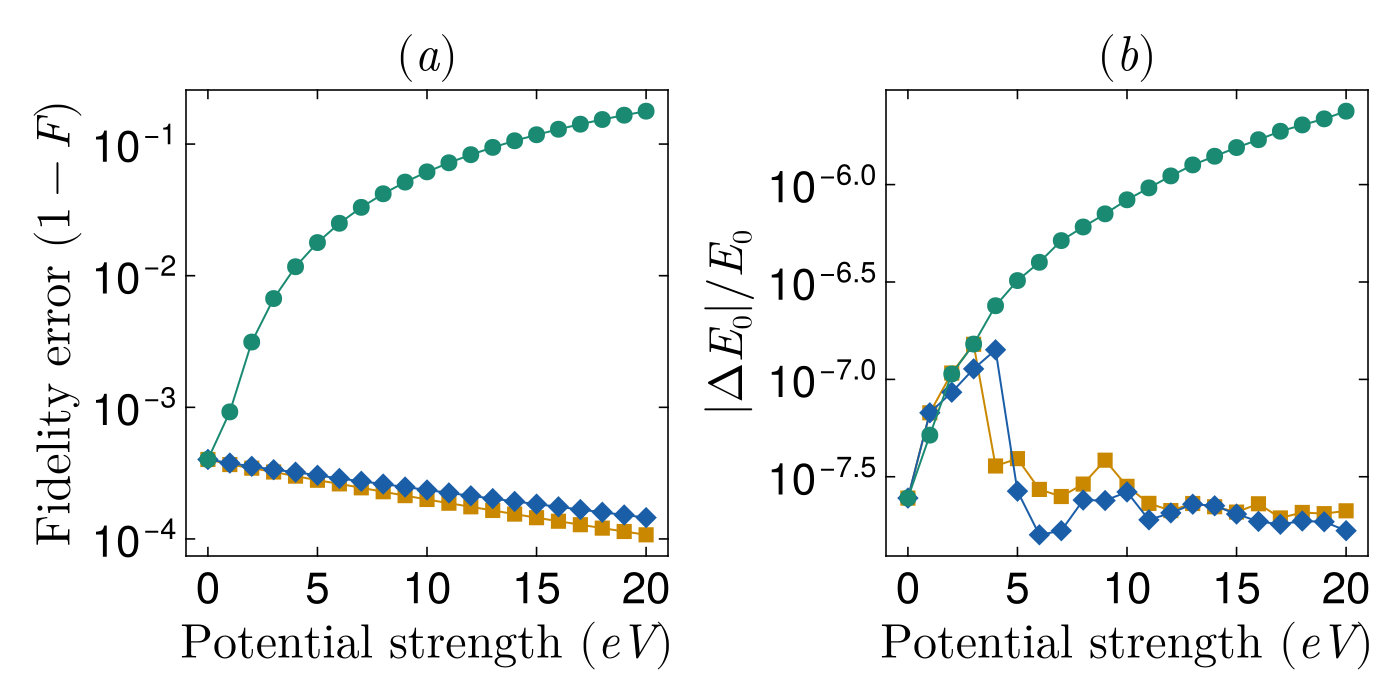

In [ ]:
using CairoMakie
using JLD2


set_theme!(Theme(
    fontsize = 11,
    font = "Times New Roman",
    backgroundcolor = :white,

    Axis = (
        xgridvisible = false,
        ygridvisible = false,
        spinewidth = 0.8,
        xtickwidth = 0.8,
        ytickwidth = 0.8,
        xticksize = 5,
        yticksize = 5,
        titlesize = 24,
        xlabelsize = 24,
        ylabelsize = 24,
        xticklabelsize = 22,
        yticklabelsize = 22,
		xtickalign = 1,
		ytickalign = 1,
		xminortickalign = 1,
		yminortickalign = 1,
		xticksmirrored = true,
		yticksmirrored = true,
    ),

    Lines = (
        linewidth = 1,
    ),

    Legend = (
        framevisible = true,
        framewidth = 1.5,
        labelsize = 11,
        patchsize = (30, 15),
        backgroundcolor = :white,
    )
))


function plot_series!(ax, x, y; color, linestyle, marker)  # ← added marker argument
    lines!(ax, x, y;
        color     = color,
        linestyle = linestyle,
        linewidth = 1,
    )
    scatter!(ax, x, y;
        color      = color,
        markersize = 12,
        marker     = marker,               # ← passed through here
    )
end

bond_dims = 5:5:50
strengths = 0:0.5:5


@load "F_bd4_2eV.jld2" F_bd
@load "E_bd4_2eV.jld2" E_bd
@load "F_st4_2eV.jld2" F_st
@load "E_st4_2eV.jld2" E_st

F_bd_2eV = deepcopy(F_bd)
E_bd_2eV = deepcopy(E_bd)
F_st_2eV = deepcopy(F_st)
E_st_2eV = deepcopy(E_st)


@load "F_bd4.jld2" F_bd
@load "E_bd4.jld2" E_bd
@load "F_st4.jld2" F_st
@load "E_st4.jld2" E_st

F_bd_10eV = deepcopy(F_bd)
E_bd_10eV = deepcopy(E_bd)
F_st_10eV = deepcopy(F_st)
E_st_10eV = deepcopy(E_st)


colors = (
    quad    = RGBf(0.788, 0.533, 0.0),
    quartic = RGBf(0.106, 0.369, 0.659),
    random  = RGBf(0.106, 0.541, 0.447),
)


markers = (
    quad    = :rect,                         # square
    quartic = :diamond,                      # diamond
    random  = :circle,                       # circle
)


fig_bd = Figure(resolution = (700,350))

ax_bd1 = Axis(fig_bd[1,1],
    xlabel = L"Bond dimension $\chi$",
    ylabel = L"Fidelity error $(1-F)$",
    yscale = log10,
    title  = L"(a)"
)

ax_bd2 = Axis(fig_bd[1,2],
    xlabel = L"Bond dimension $\chi$",
    ylabel = L"$\left|\Delta E_0\right|/E_0$",
    yscale = log10,
    title  = L"(b)"
)

# --- Fidelity ---
plot_series!(ax_bd1, bond_dims, 1 .- F_bd_2eV[:quad];    color=colors.quad,    linestyle=:solid, marker=markers.quad)
plot_series!(ax_bd1, bond_dims, 1 .- F_bd_2eV[:quartic]; color=colors.quartic, linestyle=:solid, marker=markers.quartic)
plot_series!(ax_bd1, bond_dims, 1 .- F_bd_2eV[:random];  color=colors.random,  linestyle=:solid, marker=markers.random)

plot_series!(ax_bd1, bond_dims, 1 .- F_bd_10eV[:quad];    color=colors.quad,    linestyle=:dash, marker=markers.quad)
plot_series!(ax_bd1, bond_dims, 1 .- F_bd_10eV[:quartic]; color=colors.quartic, linestyle=:dash, marker=markers.quartic)
plot_series!(ax_bd1, bond_dims, 1 .- F_bd_10eV[:random];  color=colors.random,  linestyle=:dash, marker=markers.random)

# --- Energy ---
plot_series!(ax_bd2, bond_dims, E_bd_2eV[:quad];    color=colors.quad,    linestyle=:solid, marker=markers.quad)
plot_series!(ax_bd2, bond_dims, E_bd_2eV[:quartic]; color=colors.quartic, linestyle=:solid, marker=markers.quartic)
plot_series!(ax_bd2, bond_dims, E_bd_2eV[:random];  color=colors.random,  linestyle=:solid, marker=markers.random)

plot_series!(ax_bd2, bond_dims, E_bd_10eV[:quad];    color=colors.quad,    linestyle=:dash, marker=markers.quad)
plot_series!(ax_bd2, bond_dims, E_bd_10eV[:quartic]; color=colors.quartic, linestyle=:dash, marker=markers.quartic)
plot_series!(ax_bd2, bond_dims, E_bd_10eV[:random];  color=colors.random,  linestyle=:dash, marker=markers.random)

save("BondDimension_TwoPanel_PRL.pdf", fig_bd)
fig_bd


fig_st = Figure(resolution = (700, 350))

ax_st1 = Axis(fig_st[1,1],
    xlabel = L"Potential strength $(eV)$",
    ylabel = L"Fidelity error $(1-F)$",
    yscale = log10,
    title  = L"(a)",
)

ax_st2 = Axis(fig_st[1,2],
    xlabel = L"Potential strength $(eV)$",
    ylabel = L"$\left|\Delta E_0\right|/E_0$",
    yscale = log10,
    title  = L"(b)",
)

strengths = 0:20

# --- Fidelity ---
plot_series!(ax_st1, strengths, 1 .- F_st_10eV[:quad];    color=colors.quad,    linestyle=:solid, marker=markers.quad)
plot_series!(ax_st1, strengths, 1 .- F_st_10eV[:quartic]; color=colors.quartic, linestyle=:solid, marker=markers.quartic)
plot_series!(ax_st1, strengths, 1 .- F_st_10eV[:random];  color=colors.random,  linestyle=:solid, marker=markers.random)

# --- Energy ---
plot_series!(ax_st2, strengths, E_st_10eV[:quad];    color=colors.quad,    linestyle=:solid, marker=markers.quad)
plot_series!(ax_st2, strengths, E_st_10eV[:quartic]; color=colors.quartic, linestyle=:solid, marker=markers.quartic)
plot_series!(ax_st2, strengths, E_st_10eV[:random];  color=colors.random,  linestyle=:solid, marker=markers.random)

save("Strength_TwoPanel_PRL.pdf", fig_st)
fig_st